# SpaceX Falcon 9 – EDA with Data Visualization
Explore how flight number, payload, launch site and orbit relate to landing success, then engineer features for modeling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("data/dataset_part_2.csv")
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


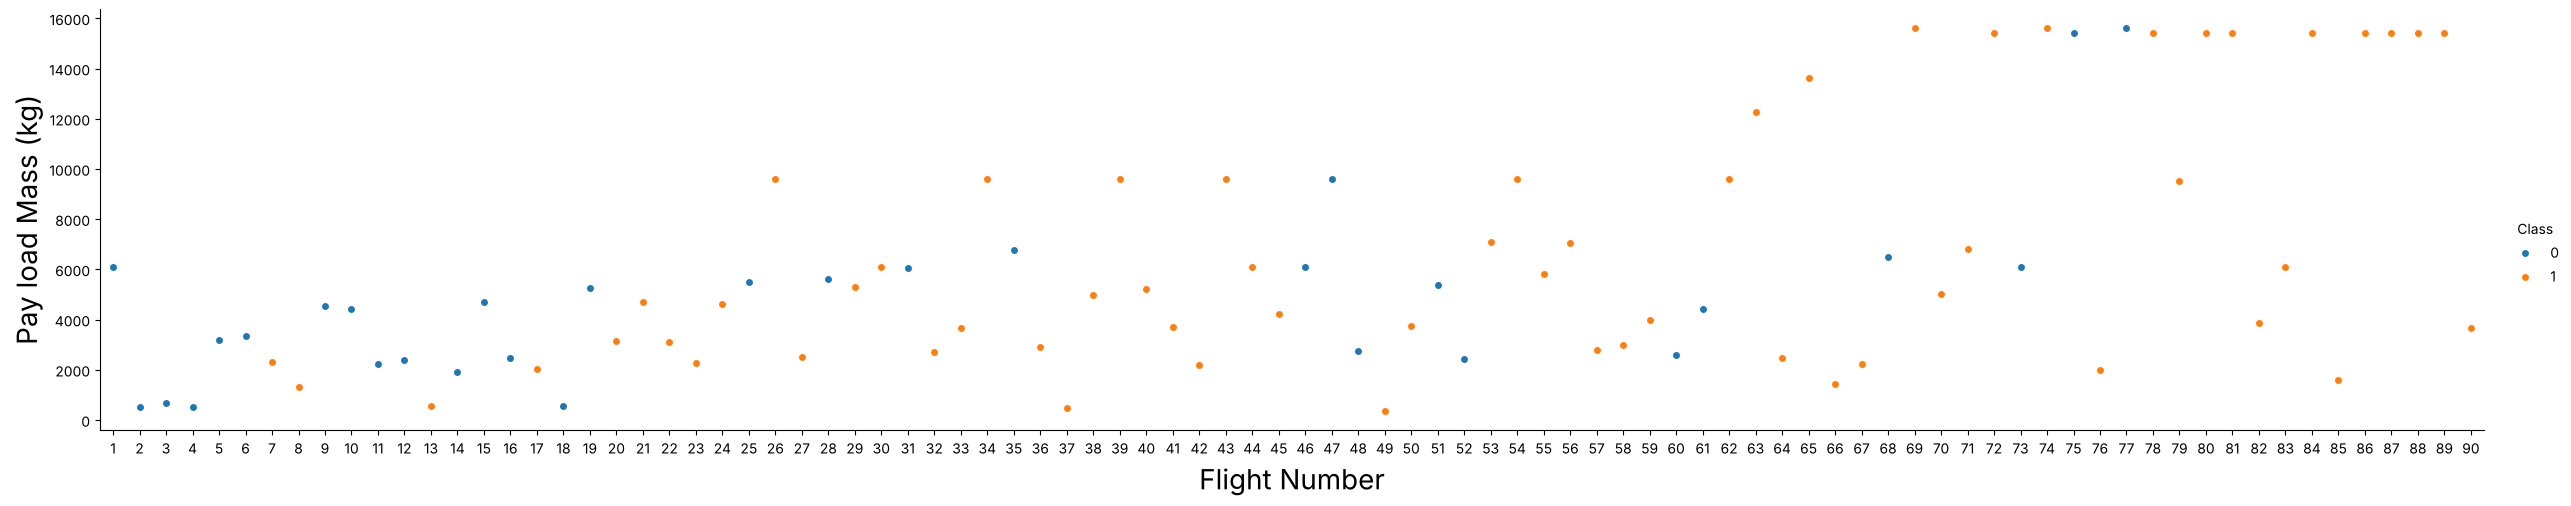

In [2]:
sns.catplot(y="PayloadMass", x="FlightNumber", hue="Class", data=df, aspect=5)
plt.xlabel("Flight Number", fontsize=20); plt.ylabel("Pay load Mass (kg)", fontsize=20)
plt.show()

## Task 1: Relationship between Flight Number and Launch Site

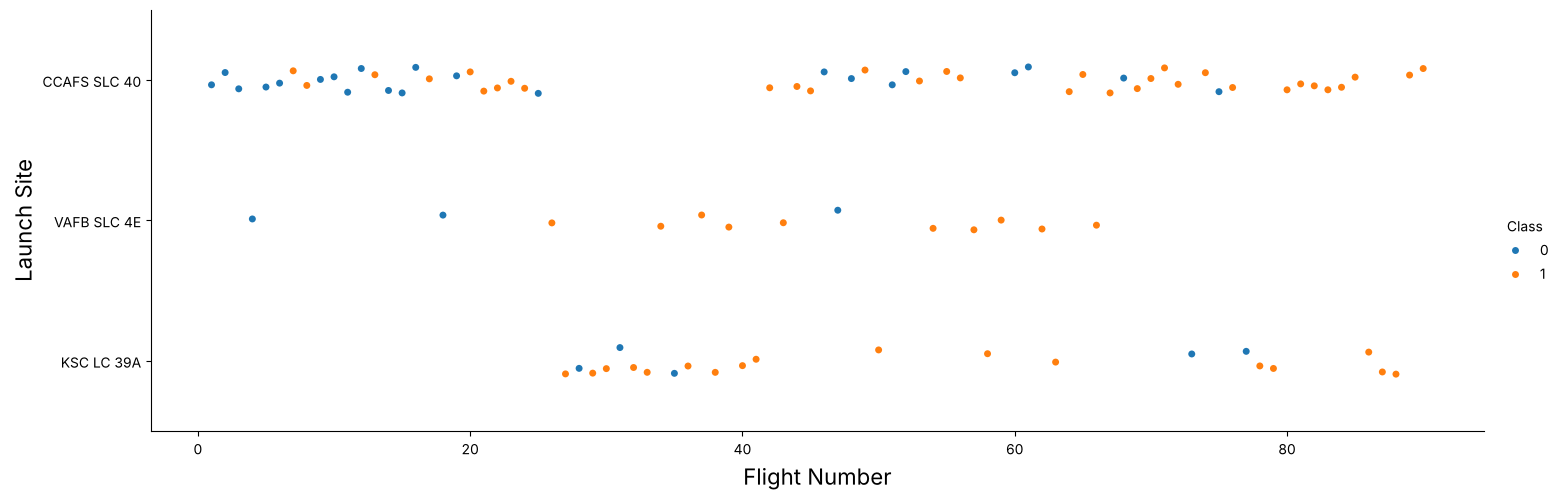

In [3]:
sns.catplot(y="LaunchSite", x="FlightNumber", hue="Class", data=df, aspect=3)
plt.xlabel("Flight Number", fontsize=16); plt.ylabel("Launch Site", fontsize=16)
plt.show()

Later flights succeed far more often at every site. CCAFS SLC 40 has the most launches and most of the early failures.

## Task 2: Relationship between Payload Mass and Launch Site

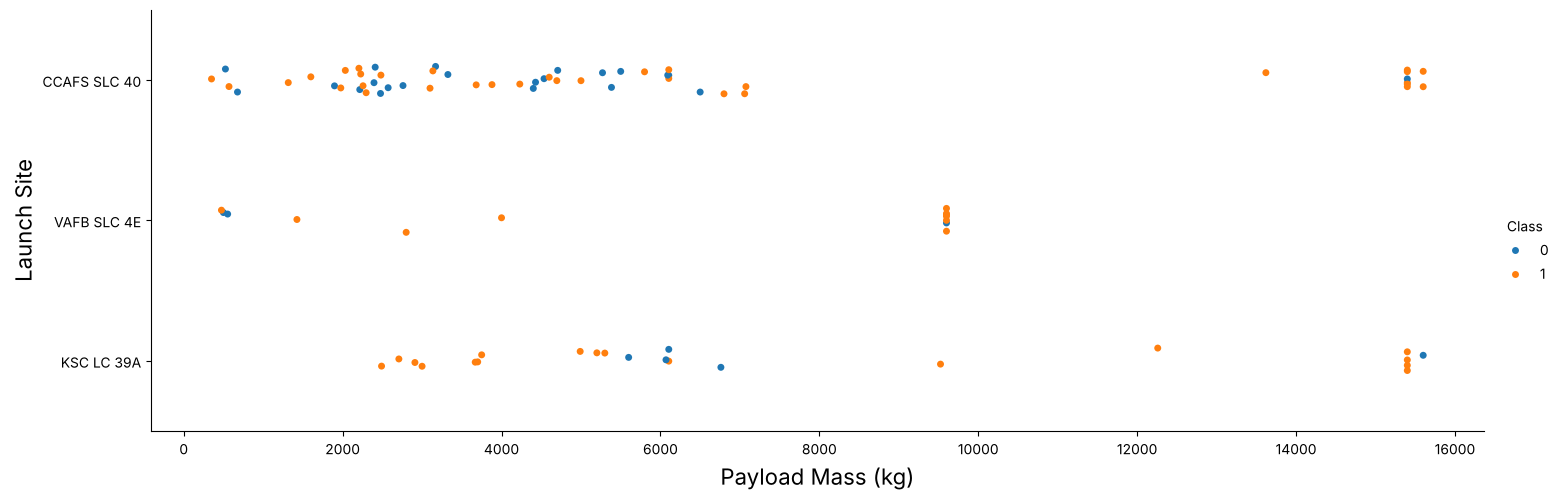

In [4]:
sns.catplot(y="LaunchSite", x="PayloadMass", hue="Class", data=df, aspect=3)
plt.xlabel("Payload Mass (kg)", fontsize=16); plt.ylabel("Launch Site", fontsize=16)
plt.show()

VAFB SLC 4E launches no payload heavier than 10,000 kg. The heaviest payloads come from the Florida sites and mostly land.

## Task 3: Success rate of each orbit type

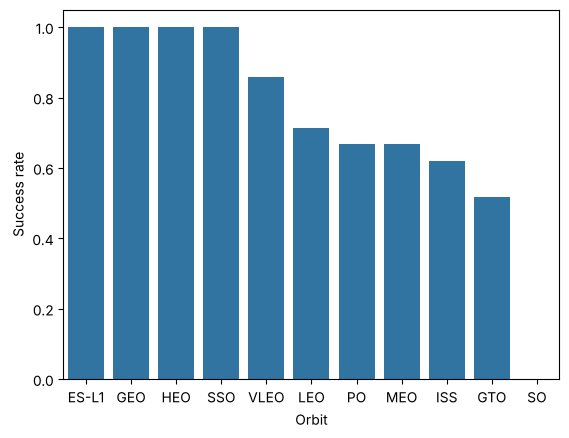

,Orbit,Class
0,ES-L1,1.000000
1,GEO,1.000000
2,HEO,1.000000
3,SSO,1.000000
4,VLEO,0.857143
5,LEO,0.714286
6,PO,0.666667
7,MEO,0.666667
8,ISS,0.619048
9,GTO,0.518519


In [5]:
orbit_rate = df.groupby("Orbit")["Class"].mean().sort_values(ascending=False).reset_index()
sns.barplot(x="Orbit", y="Class", data=orbit_rate)
plt.ylabel("Success rate"); plt.show()
orbit_rate

ES-L1, GEO, HEO and SSO have a 100% success rate; GTO is lowest among the common orbits at about 52%.

## Task 4: Relationship between Flight Number and Orbit type

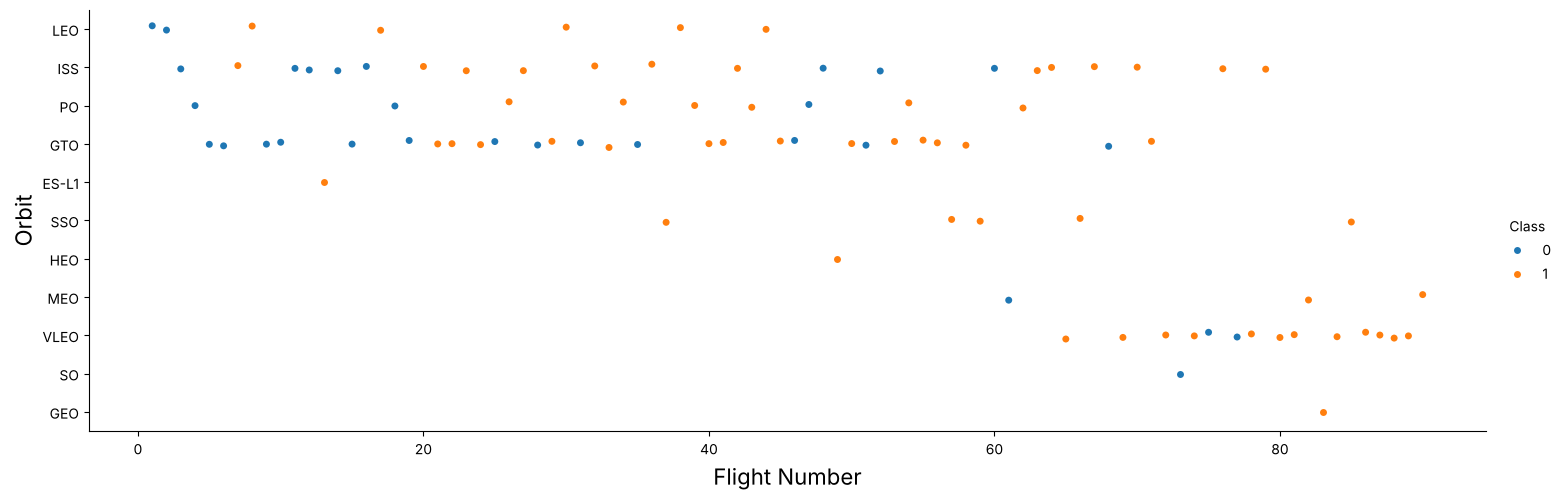

In [6]:
sns.catplot(y="Orbit", x="FlightNumber", hue="Class", data=df, aspect=3)
plt.xlabel("Flight Number", fontsize=16); plt.ylabel("Orbit", fontsize=16)
plt.show()

In LEO, success tracks flight number; in GTO there is no clear relationship.

## Task 5: Relationship between Payload Mass and Orbit type

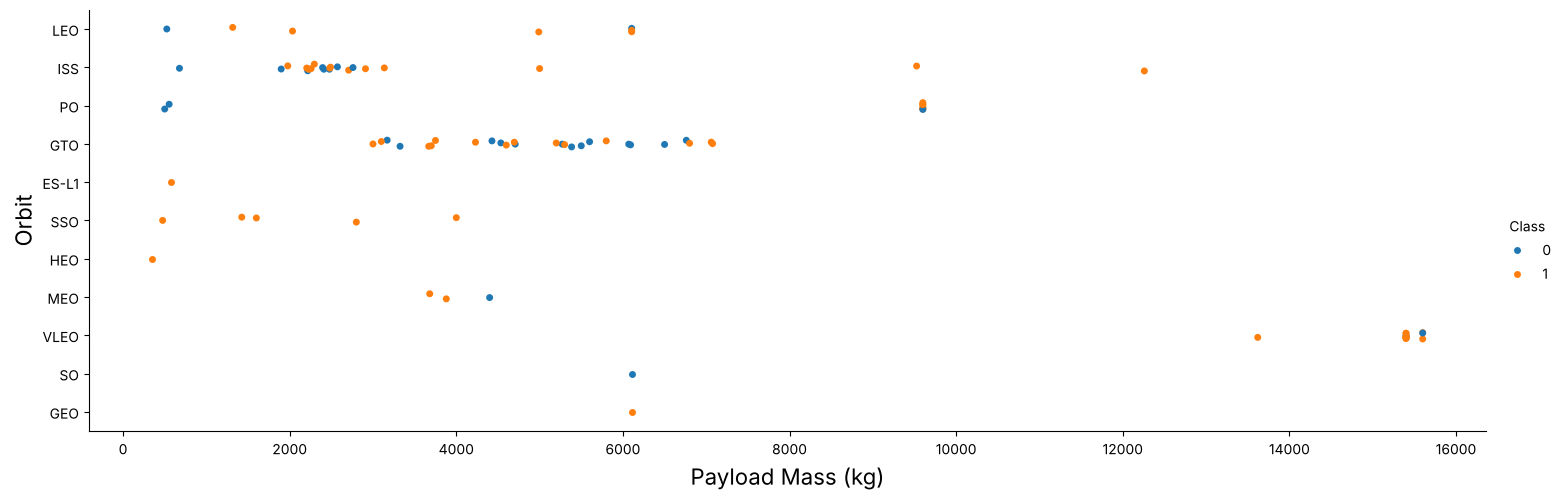

In [7]:
sns.catplot(y="Orbit", x="PayloadMass", hue="Class", data=df, aspect=3)
plt.xlabel("Payload Mass (kg)", fontsize=16); plt.ylabel("Orbit", fontsize=16)
plt.show()

Heavy payloads land well for PO, ISS and VLEO. GTO results are mixed across its payload range.

## Task 6: Launch success yearly trend

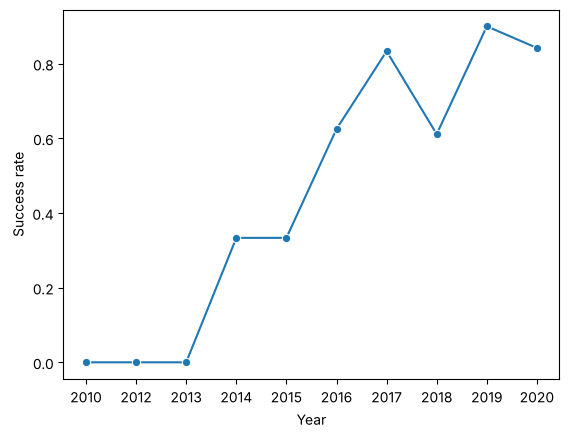

,Year,Class
0,2010,0.000000
1,2012,0.000000
2,2013,0.000000
3,2014,0.333333
4,2015,0.333333
5,2016,0.625000
6,2017,0.833333
7,2018,0.611111
8,2019,0.900000
9,2020,0.842105


In [8]:
year = []
def Extract_year():
    for i in df["Date"]:
        year.append(i.split("-")[0])
    return year
Extract_year()
df["Year"] = year
yearly = df.groupby("Year")["Class"].mean().reset_index()
sns.lineplot(x="Year", y="Class", data=yearly, marker="o")
plt.ylabel("Success rate"); plt.show()
yearly

Success rose from 0% before 2014 to 90% in 2019.

## Features engineering

In [9]:
features = df[['FlightNumber', 'PayloadMass', 'Orbit', 'LaunchSite', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


## Task 7: Create dummy variables for categorical columns

In [10]:
features_one_hot = pd.get_dummies(features, columns=['Orbit', 'LaunchSite', 'LandingPad', 'Serial'])
features_one_hot.head()

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1,6104.959412,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
1,2,525.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
2,3,677.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
3,4,500.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False
4,5,3170.000000,1,False,False,False,1.0,0,False,False,...,False,False,False,False,False,False,False,False,False,False


## Task 8: Cast all numeric columns to float64

In [11]:
features_one_hot = features_one_hot.astype('float64')
features_one_hot.to_csv('data/dataset_part_3.csv', index=False)
features_one_hot.shape

(90, 80)